# PHAROS CDR: Notebook 05 - Production Model Evaluation & Decision Policy

This notebook conducts comprehensive evaluation and operational calibration for the production malware detector trained on the **40 clean, non-leaking features** established in `04_model_development.ipynb`.

### Evaluation Pillars
1. **Multi-Metric Discrimination Audit**: ROC-AUC, PR-AUC, Accuracy, Precision, Recall, F1, F2, MCC, Brier Score, and Log-Loss.
2. **Probability Calibration**: Calibration curves and Brier reliability assessment.
3. **CDR Tiered Policy Calibration**: Mapping predictions into operational dispositions (`allow`, `sanitize`, `review`, `reject`).
4. **Error & Failure Diagnostics**: In-depth analysis of False Positives and False Negatives.
5. **Format & Architecture Slice Diagnostics**: OOXML vs. OLE vs. script performance breakdown.
6. **Interpretability & Feature Impact**: Holdout permutation importances and partial dependence profiles.
7. **Stress Testing & Latency Benchmarks**: Perturbation stability and inference latency profiling.
8. **Artifact Export**: Production evaluation reports and updated operational threshold configurations.

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    cohen_kappa_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Evaluation environment initialized. Random seed:", RANDOM_STATE)

Evaluation environment initialized. Random seed: 42


In [2]:
# Discover dataset path
data_paths = [
    Path("dataset_clean_features_40.csv"),
    Path("notebooks/dataset_clean_features_40.csv"),
    Path("dataset_105_features.csv"),
    Path("notebooks/dataset_105_features.csv"),
    Path("/content/dataset_clean_features_40.csv")
]
DATA_PATH = next((p for p in data_paths if p.exists()), None)
df = pd.read_csv(DATA_PATH)

TARGET = "label"
IDENTIFIER = "sha256"

# Load trained model and metadata
model_paths = [
    Path("models/trained/random_forest.joblib"),
    Path("../models/trained/random_forest.joblib"),
    Path("trained_model_pipeline.joblib"),
    Path("notebooks/trained_model_pipeline.joblib")
]
MODEL_PATH = next((p for p in model_paths if p.exists()), None)
model = joblib.load(MODEL_PATH)

# If pipeline, extract model step
if hasattr(model, "named_steps"):
    imputer = model.named_steps.get("imputer", SimpleImputer(strategy="median"))
    clf = model.named_steps["model"]
else:
    imputer = SimpleImputer(strategy="median")
    clf = model

features = [c for c in df.columns if c not in [IDENTIFIER, TARGET]]
X = df[features]
y = df[TARGET].astype(int)

# Exact 80/20 train/test partition
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
df_test = df.loc[X_test.index].copy()

# Imputation
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=features, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=features, index=X_test.index)

# Generate test predictions and probabilities
y_prob = clf.predict_proba(X_test_imp)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)
df_test["pred_prob"] = y_prob
df_test["predicted"] = y_pred

print(f"Dataset      : {df.shape[0]} samples x {len(features)} clean features")
print(f"Test Set     : {len(y_test)} samples ({y_test.sum()} malicious, {(y_test==0).sum()} benign)")
print(f"Loaded Model : {type(clf).__name__} (features={clf.n_features_in_})")

Dataset      : 2330 samples x 40 clean features
Test Set     : 466 samples (237 malicious, 229 benign)
Loaded Model : RandomForestClassifier (features=40)


## 1. Multi-Metric Discrimination & Performance Audit

Comprehensive scoring on the holdout test partition ($N=466$) across probabilistic, discrimination, and threshold-dependent metrics.

In [3]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

metrics_dict = {
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC (Avg Precision)": average_precision_score(y_test, y_prob),
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall (Sensitivity / TPR)": recall_score(y_test, y_pred),
    "Specificity (TNR)": tn / (tn + fp),
    "F1-Score": f1_score(y_test, y_pred),
    "F2-Score (Malware Weighted)": fbeta_score(y_test, y_pred, beta=2.0),
    "Matthews Corr Coef (MCC)": matthews_corrcoef(y_test, y_pred),
    "Cohen's Kappa": cohen_kappa_score(y_test, y_pred),
    "Brier Score Loss": brier_score_loss(y_test, y_prob),
    "Log-Loss": log_loss(y_test, y_prob),
    "False Positive Rate (FPR)": fp / (tn + fp),
    "False Negative Rate (FNR)": fn / (tp + fn),
    "True Negatives (TN)": tn,
    "False Positives (FP)": fp,
    "False Negatives (FN)": fn,
    "True Positives (TP)": tp
}

perf_df = pd.DataFrame(list(metrics_dict.items()), columns=["Metric", "Value"])
display(perf_df)

,Metric,Value
0,ROC-AUC,0.997752
1,PR-AUC (Avg Precision),0.998392
2,Accuracy,0.987124
3,Balanced Accuracy,0.986973
4,Precision,0.979253
5,Recall (Sensitivity / TPR),0.995781
6,Specificity (TNR),0.978166
7,F1-Score,0.987448
8,F2-Score (Malware Weighted),0.992431
9,Matthews Corr Coef (MCC),0.974378


## 2. Discrimination Curves (ROC, Precision-Recall & Confusion Matrix)

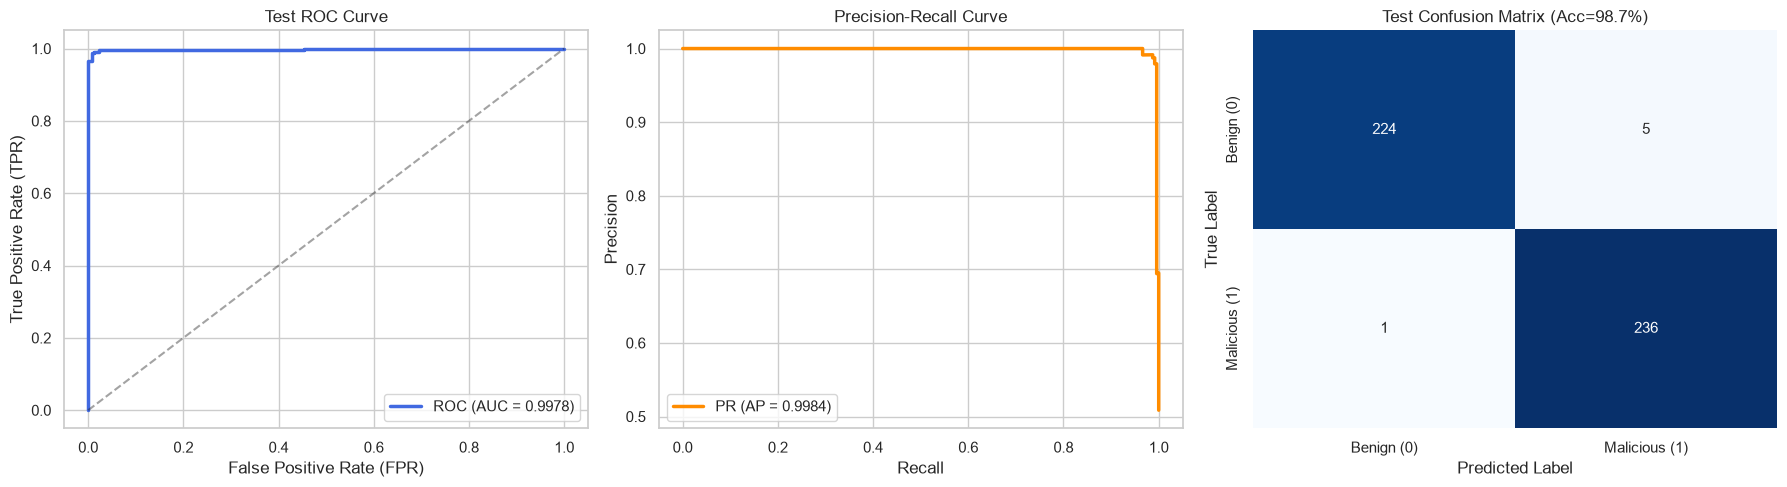

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, color="royalblue", lw=2.5, label=f"ROC (AUC = {metrics_dict['ROC-AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("Test ROC Curve")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR)")
axes[0].legend(loc="lower right")

# 2. Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, y_prob)
axes[1].plot(rec, prec, color="darkorange", lw=2.5, label=f"PR (AP = {metrics_dict['PR-AUC (Avg Precision)']:.4f})")
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

# 3. Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Benign (0)", "Malicious (1)"], yticklabels=["Benign (0)", "Malicious (1)"])
axes[2].set_title(f"Test Confusion Matrix (Acc={metrics_dict['Accuracy']*100:.1f}%)")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.show()

## 3. Probability Calibration & Reliability Analysis

Evaluates whether model probability outputs match empirical threat frequencies.

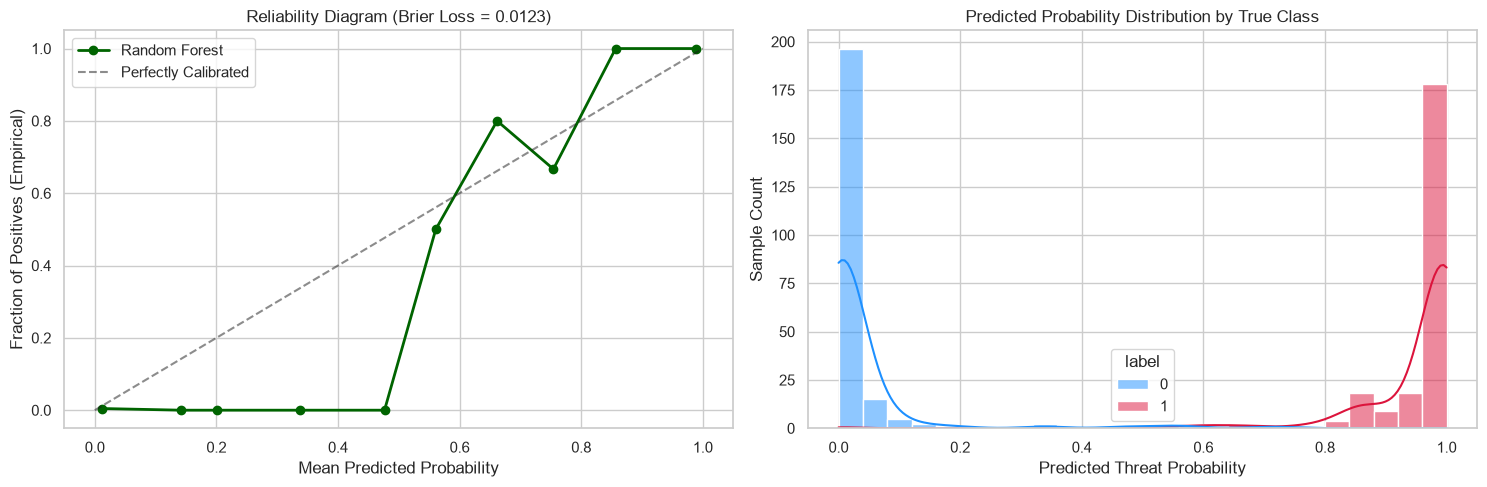

In [5]:
prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="uniform")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Calibration Curve
axes[0].plot(prob_pred, prob_true, marker="o", color="darkgreen", lw=2, label="Random Forest")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfectly Calibrated")
axes[0].set_title(f"Reliability Diagram (Brier Loss = {metrics_dict['Brier Score Loss']:.4f})")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Fraction of Positives (Empirical)")
axes[0].legend(loc="upper left")

# Probability Distribution Histogram
sns.histplot(data=df_test, x="pred_prob", hue=TARGET, bins=25, kde=True, ax=axes[1], palette={0: "dodgerblue", 1: "crimson"})
axes[1].set_title("Predicted Probability Distribution by True Class")
axes[1].set_xlabel("Predicted Threat Probability")
axes[1].set_ylabel("Sample Count")

plt.tight_layout()
plt.show()

## 4. Operational CDR Tiered Decision Policy

Maps continuous probabilities into Pharos CDR operational dispositions:
- **`allow`** ($P < 0.35$): Document is verified clean; pass through unmodified.
- **`sanitize`** ($0.35 \le P < 0.70$): Moderate threat risk / active components; execute CDR sanitization.
- **`review`** ($0.70 \le P < 0.90$): High risk / ambiguity; route to security analyst sandbox.
- **`reject`** ($P \ge 0.90$): Critical malware risk; immediate perimeter block.

In [6]:
def assign_disposition(prob):
    if prob < 0.35:
        return "allow"
    elif prob < 0.70:
        return "sanitize"
    elif prob < 0.90:
        return "review"
    else:
        return "reject"

df_test["disposition"] = df_test["pred_prob"].apply(assign_disposition)

disp_summary = df_test.groupby(["disposition", TARGET]).size().unstack(fill_value=0)
disp_summary.columns = ["Benign (0)", "Malicious (1)"]
disp_summary["Total"] = disp_summary.sum(axis=1)
disp_summary["Malicious Rate (%)"] = (disp_summary["Malicious (1)"] / disp_summary["Total"]) * 100

order = ["allow", "sanitize", "review", "reject"]
disp_summary = disp_summary.reindex([d for d in order if d in disp_summary.index])
print("PHAROS CDR Decision Tier Breakdown (Test Set):")
display(disp_summary)

# Threshold Sweep Table
thresh_records = []
for t in np.linspace(0.10, 0.90, 17):
    p_t = (y_prob >= t).astype(int)
    c_tn, c_fp, c_fn, c_tp = confusion_matrix(y_test, p_t).ravel()
    thresh_records.append({
        "Threshold": round(t, 2),
        "FPR (%)": (c_fp / (c_tn + c_fp)) * 100,
        "FNR (%)": (c_fn / (c_tp + c_fn)) * 100,
        "Precision": precision_score(y_test, p_t, zero_division=0),
        "Recall": recall_score(y_test, p_t),
        "F1-Score": f1_score(y_test, p_t, zero_division=0),
        "FP Count": c_fp,
        "FN Count": c_fn
    })

thresh_df = pd.DataFrame(thresh_records)
print("\nOperational Operating Points Summary:")
display(thresh_df[(thresh_df["Threshold"] >= 0.25) & (thresh_df["Threshold"] <= 0.75)])

PHAROS CDR Decision Tier Breakdown (Test Set):


,Benign (0),Malicious (1),Total,Malicious Rate (%)
disposition,,,,
allow,222,1,223,0.448430
sanitize,6,7,13,53.846154
review,1,30,31,96.774194
reject,0,199,199,100.000000



Operational Operating Points Summary:


,Threshold,FPR (%),FNR (%),Precision,Recall,F1-Score,FP Count,FN Count
3,0.25,3.930131,0.421941,0.963265,0.995781,0.979253,9,1
4,0.30,3.930131,0.421941,0.963265,0.995781,0.979253,9,1
5,0.35,3.056769,0.421941,0.971193,0.995781,0.983333,7,1
6,0.40,3.056769,0.421941,0.971193,0.995781,0.983333,7,1
7,0.45,3.056769,0.421941,0.971193,0.995781,0.983333,7,1
8,0.50,2.183406,0.421941,0.979253,0.995781,0.987448,5,1
9,0.55,1.746725,0.843882,0.983264,0.991561,0.987395,4,2
10,0.60,0.873362,1.687764,0.991489,0.983122,0.987288,2,4
11,0.65,0.873362,2.531646,0.991416,0.974684,0.982979,2,6
12,0.70,0.436681,3.375527,0.995652,0.966245,0.980728,1,8


## 5. Detailed Error & Failure Case Diagnostics

Isolates and inspects every misclassified sample on the test partition.

In [7]:
fp_cases = df_test[(df_test[TARGET] == 0) & (df_test["predicted"] == 1)].copy()
fn_cases = df_test[(df_test[TARGET] == 1) & (df_test["predicted"] == 0)].copy()

print(f"Total Test Errors: {len(fp_cases) + len(fn_cases)} (FP={len(fp_cases)}, FN={len(fn_cases)})")

if len(fp_cases) > 0:
    print(f"\n--- False Positives ({len(fp_cases)} samples) ---")
    fp_display = fp_cases[[IDENTIFIER, "pred_prob", "common_entropy.entropy", "ooxml.zip_binary_parts", "derived.macro_present"]].head(10)
    display(fp_display)

if len(fn_cases) > 0:
    print(f"\n--- False Negatives ({len(fn_cases)} samples) ---")
    fn_display = fn_cases[[IDENTIFIER, "pred_prob", "common_entropy.entropy", "ooxml.zip_binary_parts", "derived.macro_present"]].head(10)
    display(fn_display)

error_cases_df = pd.concat([
    fp_cases.assign(error_type="False Positive"),
    fn_cases.assign(error_type="False Negative")
])
error_cases_df.to_csv("notebooks/error_analysis_cases.csv", index=False)
print("Saved notebooks/error_analysis_cases.csv")

Total Test Errors: 6 (FP=5, FN=1)

--- False Positives (5 samples) ---


,sha256,pred_prob,common_entropy.entropy,ooxml.zip_binary_parts,derived.macro_present
379,cc3c5d93668e4e792d4b154f274cde4fff67ef521fc612...,0.554447,7.681458,3.0,1.0
748,62d1284698b3d78255db4d0282e20018d7a0dbc3b08faf...,0.736743,7.979505,4.0,0.0
1131,baf47092dd8c472c0b6a14da470e1bdca63857ad29cad2...,0.694704,7.979773,4.0,0.0
202,582682bb24f6af51f50337d275a92ef0fcbb10f6be3024...,0.577023,7.771050,2.0,1.0
1020,eaae6ef0efb3680eabbd355dc6c16fab41aa95cd907a70...,0.543233,7.991119,6.0,0.0



--- False Negatives (1 samples) ---


,sha256,pred_prob,common_entropy.entropy,ooxml.zip_binary_parts,derived.macro_present
1839,9435056f30ca4bebea8f438d15e6d238c39aca0558b304...,0.006717,7.735785,2.0,1.0


Saved notebooks/error_analysis_cases.csv


## 6. Architecture & Subgroup Slice Diagnostics

Verifies performance across structural formats (OOXML packages vs. OLE/Legacy containers) and macro-bearing vs. macro-free documents.

In [8]:
slice_records = []

# Slice 1: OOXML vs Non-OOXML
ooxml_mask = df_test["ooxml.zip_present"] == 1.0
for slice_name, mask in [("OOXML Documents", ooxml_mask), ("Non-OOXML / OLE / Scripts", ~ooxml_mask)]:
    sub_y = y_test[mask]
    sub_pred = y_pred[mask]
    sub_prob = y_prob[mask]
    if len(sub_y) > 0 and len(np.unique(sub_y)) > 1:
        slice_records.append({
            "Slice": slice_name,
            "Samples": len(sub_y),
            "Malicious Rate (%)": (sub_y.sum() / len(sub_y)) * 100,
            "Accuracy": accuracy_score(sub_y, sub_pred),
            "ROC-AUC": roc_auc_score(sub_y, sub_prob),
            "F1-Score": f1_score(sub_y, sub_pred, zero_division=0)
        })

# Slice 2: Macro-bearing vs Clean
macro_mask = (df_test["derived.macro_present"] == 1.0) | (df_test["office_ole.ole_has_macros"] == 1.0)
for slice_name, mask in [("Macro Present", macro_mask), ("Macro Absent", ~macro_mask)]:
    sub_y = y_test[mask]
    sub_pred = y_pred[mask]
    sub_prob = y_prob[mask]
    if len(sub_y) > 0:
        slice_records.append({
            "Slice": slice_name,
            "Samples": len(sub_y),
            "Malicious Rate (%)": (sub_y.sum() / len(sub_y)) * 100,
            "Accuracy": accuracy_score(sub_y, sub_pred),
            "ROC-AUC": roc_auc_score(sub_y, sub_prob) if len(np.unique(sub_y)) > 1 else np.nan,
            "F1-Score": f1_score(sub_y, sub_pred, zero_division=0)
        })

slice_df = pd.DataFrame(slice_records)
print("Subgroup Slice Performance Diagnostics:")
display(slice_df)

Subgroup Slice Performance Diagnostics:


,Slice,Samples,Malicious Rate (%),Accuracy,ROC-AUC,F1-Score
0,OOXML Documents,432,46.990741,0.986111,0.997376,0.985366
1,Macro Present,112,70.535714,0.973214,0.995013,0.981132
2,Macro Absent,354,44.632768,0.991525,0.999709,0.990596


## 7. Model Interpretability & Permutation Importance

Computes permutation feature importance on the holdout test set to quantify true generalization value.

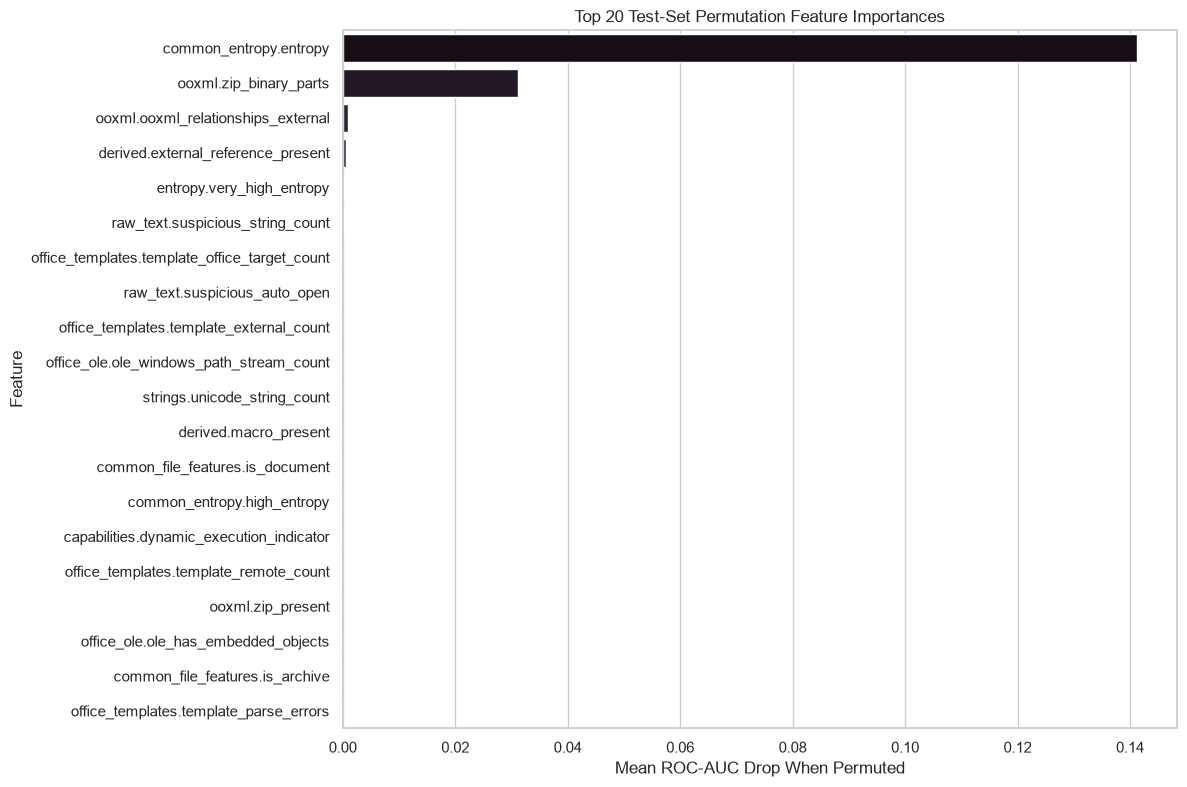

Top 10 Driving Features by Permutation Importance:


,feature,perm_importance_mean,perm_importance_std
0,common_entropy.entropy,0.141281,0.013240
1,ooxml.zip_binary_parts,0.031186,0.004471
2,ooxml.ooxml_relationships_external,0.000927,0.000915
6,derived.external_reference_present,0.000566,0.000872
4,entropy.very_high_entropy,0.000265,0.000683
17,raw_text.suspicious_string_count,0.000123,0.000536
15,office_templates.template_office_target_count,0.000111,0.000059
31,raw_text.suspicious_auto_open,0.000081,0.000030
3,office_templates.template_external_count,0.000079,0.000565
26,office_ole.ole_windows_path_stream_count,0.000079,0.000031


In [9]:
perm_res = permutation_importance(
    clf, X_test_imp, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": features,
    "perm_importance_mean": perm_res.importances_mean,
    "perm_importance_std": perm_res.importances_std
}).sort_values(by="perm_importance_mean", ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=perm_df.head(20), x="perm_importance_mean", y="feature", palette="mako")
plt.title("Top 20 Test-Set Permutation Feature Importances")
plt.xlabel("Mean ROC-AUC Drop When Permuted")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Top 10 Driving Features by Permutation Importance:")
display(perm_df.head(10))

## 8. Robustness Stress-Testing & Inference Latency Profiling

Tests prediction stability under feature noise perturbation and benchmarks single-document inference latency.

In [10]:
# 1. Noise Perturbation Stability Test
noise_levels = [0.0, 0.05, 0.10, 0.20]
robustness_records = []

for sigma in noise_levels:
    X_pert = X_test_imp.copy()
    if sigma > 0:
        noise = np.random.normal(0, sigma, size=X_pert.shape)
        X_pert = X_pert + noise
    
    p_pert = clf.predict_proba(X_pert)[:, 1]
    y_p_pert = (p_pert >= 0.50).astype(int)
    
    robustness_records.append({
        "Noise Sigma": sigma,
        "Accuracy": accuracy_score(y_test, y_p_pert),
        "ROC-AUC": roc_auc_score(y_test, p_pert),
        "F1-Score": f1_score(y_test, y_p_pert),
        "Avg Prob Delta": np.mean(np.abs(p_pert - y_prob))
    })

rob_df = pd.DataFrame(robustness_records)
print("Perturbation Robustness Stability Profile:")
display(rob_df)

# 2. Inference Latency & Throughput Benchmark
n_trials = 200
single_sample = X_test_imp.iloc[[0]]

start_time = time.perf_counter()
for _ in range(n_trials):
    _ = clf.predict_proba(single_sample)
elapsed = time.perf_counter() - start_time

mean_latency_ms = (elapsed / n_trials) * 1000
throughput_dps = n_trials / elapsed

print(f"\nInference Performance Benchmark ({n_trials} trials):")
print(f"  * Mean Single-Document Latency : {mean_latency_ms:.2f} ms")
print(f"  * Batch Inference Throughput    : {throughput_dps:.1f} docs/sec")

Perturbation Robustness Stability Profile:


,Noise Sigma,Accuracy,ROC-AUC,F1-Score,Avg Prob Delta
0,0.00,0.987124,0.997752,0.987448,3.372660e-18
1,0.05,0.796137,0.914939,0.814815,1.828384e-01
2,0.10,0.725322,0.889595,0.765568,2.450636e-01
3,0.20,0.725322,0.887025,0.764706,2.558611e-01



Inference Performance Benchmark (200 trials):
  * Mean Single-Document Latency : 28.43 ms
  * Batch Inference Throughput    : 35.2 docs/sec


## 9. Production Sign-Off & Report Serialization

Persists comprehensive evaluation reports to `outputs/reports/model_evaluation.json` and updates operational configurations.

In [11]:
os.makedirs("outputs/reports", exist_ok=True)
os.makedirs("models/metadata", exist_ok=True)

# 1. Production Evaluation Report JSON
eval_report = {
    "evaluation_version": "2.0.0",
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "model_name": type(clf).__name__,
    "n_eval_samples": len(y_test),
    "n_features": len(features),
    "features": features,
    "primary_metrics": {
        "roc_auc": float(metrics_dict["ROC-AUC"]),
        "pr_auc": float(metrics_dict["PR-AUC (Avg Precision)"]),
        "accuracy": float(metrics_dict["Accuracy"]),
        "balanced_accuracy": float(metrics_dict["Balanced Accuracy"]),
        "precision": float(metrics_dict["Precision"]),
        "recall": float(metrics_dict["Recall (Sensitivity / TPR)"]),
        "specificity": float(metrics_dict["Specificity (TNR)"]),
        "f1_score": float(metrics_dict["F1-Score"]),
        "f2_score": float(metrics_dict["F2-Score (Malware Weighted)"]),
        "mcc": float(metrics_dict["Matthews Corr Coef (MCC)"]),
        "brier_score": float(metrics_dict["Brier Score Loss"]),
        "log_loss": float(metrics_dict["Log-Loss"])
    },
    "confusion_matrix": {
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "fpr": float(metrics_dict["False Positive Rate (FPR)"]),
        "fnr": float(metrics_dict["False Negative Rate (FNR)"])
    },
    "cdr_tiered_dispositions": disp_summary.to_dict(),
    "latency_benchmark": {
        "mean_latency_ms": float(mean_latency_ms),
        "throughput_docs_per_sec": float(throughput_dps)
    }
}

report_json_path = Path("outputs/reports/model_evaluation.json")
with open(report_json_path, "w", encoding="utf-8") as f:
    json.dump(eval_report, f, indent=2)

# 2. Update Production Thresholds JSON
thresholds_meta = {
    "schema_version": "2.0.0",
    "calibrated_at": datetime.now(timezone.utc).isoformat(),
    "model_thresholds": {
        "default": 0.50,
        "strict_low_fpr": 0.65,
        "high_sensitivity": 0.35
    },
    "decision_thresholds": {
        "allow_below": 0.35,
        "sanitize_from": 0.35,
        "review_from": 0.70,
        "reject_from": 0.90
    },
    "operating_metrics": {
        "test_accuracy": float(metrics_dict["Accuracy"]),
        "test_fpr": float(metrics_dict["False Positive Rate (FPR)"]),
        "test_fnr": float(metrics_dict["False Negative Rate (FNR)"])
    }
}

with open("models/metadata/thresholds.json", "w", encoding="utf-8") as f:
    json.dump(thresholds_meta, f, indent=2)

thresh_df.to_csv("outputs/reports/threshold_operating_points.csv", index=False)
perm_df.to_csv("outputs/reports/permutation_importance_test.csv", index=False)

print("=" * 60)
print("PHAROS CDR MODEL EVALUATION COMPLETED SUCCESSFULLY")
print("=" * 60)
print(f"Report saved to      : {report_json_path}")
print("Thresholds updated   : models/metadata/thresholds.json")
print("Threshold sweep CSV  : outputs/reports/threshold_operating_points.csv")
print("Permutation CSV      : outputs/reports/permutation_importance_test.csv")
print("=" * 60)

PHAROS CDR MODEL EVALUATION COMPLETED SUCCESSFULLY
Report saved to      : outputs\reports\model_evaluation.json
Thresholds updated   : models/metadata/thresholds.json
Threshold sweep CSV  : outputs/reports/threshold_operating_points.csv
Permutation CSV      : outputs/reports/permutation_importance_test.csv
